In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df = pd.read_csv("sentiment_reviews.csv")

df.head()

,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative


In [9]:
print("Dataset Shape:", df.shape)
print("\nDataset Information:")

df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (10, 3)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    10 non-null     int64
 1   review_text  10 non-null     str  
 2   sentiment    10 non-null     str  
dtypes: int64(1), str(2)
memory usage: 372.0 bytes

Statistical Summary:
       review_id
count   10.00000
mean     5.50000
std      3.02765
min      1.00000
25%      3.25000
50%      5.50000
75%      7.75000
max     10.00000

Missing Values:
review_id      0
review_text    0
sentiment      0
dtype: int64


In [10]:
print(df['sentiment'].value_counts())

sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64


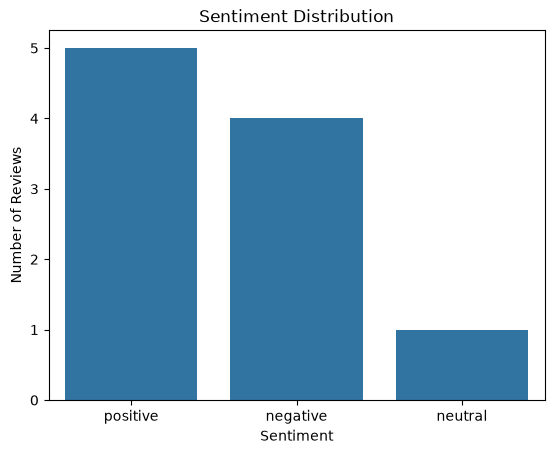

In [11]:
sns.countplot(data=df, x='sentiment')
plt.title("Sentiment Distribution")

plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [12]:
for i in range(5):
    print("Review:", df['review_text'][i])

Review: The product quality is exceptional, exceeded all my expectations!
Review: Terrible customer service and the item arrived completely damaged.
Review: Average performance, decent for the price point but nothing special.
Review: Absolutely love this! Easy to setup, robust, and works flawlessly.
Review: Stopped working after two days. Extremely disappointed with the purchase.


In [13]:
import re
import string

In [14]:
df['cleaned_text'] = df['review_text'].str.lower()
df[['review_text', 'cleaned_text']].head()

,review_text,cleaned_text
0,"The product quality is exceptional, exceeded a...","the product quality is exceptional, exceeded a..."
1,Terrible customer service and the item arrived...,terrible customer service and the item arrived...
2,"Average performance, decent for the price poin...","average performance, decent for the price poin..."
3,"Absolutely love this! Easy to setup, robust, a...","absolutely love this! easy to setup, robust, a..."
4,Stopped working after two days. Extremely disa...,stopped working after two days. extremely disa...


In [15]:
df['cleaned_text'] = df['cleaned_text'].apply(
    lambda x: re.sub(r'[^a-zA-Z\s]', '', x)
)

In [16]:
df['cleaned_text'] = df['cleaned_text'].apply(
    lambda x: re.sub(r'\s+', ' ', x).strip()
)

In [17]:
df[['review_text', 'cleaned_text']].head(10)

,review_text,cleaned_text
0,"The product quality is exceptional, exceeded a...",the product quality is exceptional exceeded al...
1,Terrible customer service and the item arrived...,terrible customer service and the item arrived...
2,"Average performance, decent for the price poin...",average performance decent for the price point...
3,"Absolutely love this! Easy to setup, robust, a...",absolutely love this easy to setup robust and ...
4,Stopped working after two days. Extremely disa...,stopped working after two days extremely disap...
5,Customer support helped resolve my setup quest...,customer support helped resolve my setup quest...
6,Delivery was slow and package was missing one ...,delivery was slow and package was missing one ...
7,Clean interface and intuitive controls. Highly...,clean interface and intuitive controls highly ...
8,"Not worth the money, plenty of better alternat...",not worth the money plenty of better alternati...
9,Great value and durable build. Would definitel...,great value and durable build would definitely...


In [18]:
pip install nltk


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [19]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

In [20]:
from nltk.tokenize import wordpunct_tokenize
df['tokens'] = df['cleaned_text'].apply(wordpunct_tokenize)
df[['cleaned_text', 'tokens']].head()

,cleaned_text,tokens
0,the product quality is exceptional exceeded al...,"[the, product, quality, is, exceptional, excee..."
1,terrible customer service and the item arrived...,"[terrible, customer, service, and, the, item, ..."
2,average performance decent for the price point...,"[average, performance, decent, for, the, price..."
3,absolutely love this easy to setup robust and ...,"[absolutely, love, this, easy, to, setup, robu..."
4,stopped working after two days extremely disap...,"[stopped, working, after, two, days, extremely..."


In [21]:
stop_words = {
    'the', 'is', 'am', 'are', 'was', 'were',
    'a', 'an', 'and', 'or', 'but', 'of',
    'in', 'on', 'at', 'to', 'for', 'with',
    'this', 'that', 'it', 'my', 'i', 'we',
    'they', 'he', 'she', 'you', 'me', 'our',
    'your', 'their', 'as', 'by', 'from',
    'have', 'has', 'had', 'be', 'been',
    'being', 'do', 'does', 'did', 'so'
}

In [22]:
negation_words = {'not', 'no', 'nor', 'never'}

custom_stopwords = stop_words - negation_words

In [23]:
df['filtered_tokens'] = df['tokens'].apply(
    lambda words: [word for word in words if word not in custom_stopwords]
)

df[['tokens', 'filtered_tokens']].head()

,tokens,filtered_tokens
0,"[the, product, quality, is, exceptional, excee...","[product, quality, exceptional, exceeded, all,..."
1,"[terrible, customer, service, and, the, item, ...","[terrible, customer, service, item, arrived, c..."
2,"[average, performance, decent, for, the, price...","[average, performance, decent, price, point, n..."
3,"[absolutely, love, this, easy, to, setup, robu...","[absolutely, love, easy, setup, robust, works,..."
4,"[stopped, working, after, two, days, extremely...","[stopped, working, after, two, days, extremely..."


In [24]:
df['processed_text'] = df['filtered_tokens'].apply(
    lambda words: ' '.join(words)
)

df[['review_text', 'processed_text']].head(10)

,review_text,processed_text
0,"The product quality is exceptional, exceeded a...",product quality exceptional exceeded all expec...
1,Terrible customer service and the item arrived...,terrible customer service item arrived complet...
2,"Average performance, decent for the price poin...",average performance decent price point nothing...
3,"Absolutely love this! Easy to setup, robust, a...",absolutely love easy setup robust works flawle...
4,Stopped working after two days. Extremely disa...,stopped working after two days extremely disap...
5,Customer support helped resolve my setup quest...,customer support helped resolve setup question...
6,Delivery was slow and package was missing one ...,delivery slow package missing one adapter cable
7,Clean interface and intuitive controls. Highly...,clean interface intuitive controls highly reco...
8,"Not worth the money, plenty of better alternat...",not worth money plenty better alternatives ava...
9,Great value and durable build. Would definitel...,great value durable build would definitely pur...


In [25]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

In [26]:
!pip install spacy


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [27]:
!python3 -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 50.2 MB/s  0:00:00eta 0:00:01

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [28]:
import spacy
nlp = spacy.load("en_core_web_sm")

In [29]:
def lemmatize_text(text):
    doc = nlp(text)
    return ' '.join([token.lemma_ for token in doc])

df['lemmatized_text'] = df['processed_text'].apply(lemmatize_text)

In [30]:
df[['processed_text', 'lemmatized_text']].head(10)

,processed_text,lemmatized_text
0,product quality exceptional exceeded all expec...,product quality exceptional exceed all expecta...
1,terrible customer service item arrived complet...,terrible customer service item arrive complete...
2,average performance decent price point nothing...,average performance decent price point nothing...
3,absolutely love easy setup robust works flawle...,absolutely love easy setup robust work flawlessly
4,stopped working after two days extremely disap...,stop work after two day extremely disappointed...
5,customer support helped resolve setup question...,customer support help resolve setup question w...
6,delivery slow package missing one adapter cable,delivery slow package miss one adapter cable
7,clean interface intuitive controls highly reco...,clean interface intuitive control highly recom...
8,not worth money plenty better alternatives ava...,not worth money plenty well alternative available
9,great value durable build would definitely pur...,great value durable build would definitely pur...


In [31]:
sentiment_percentage = df['sentiment'].value_counts(normalize=True) * 100
print(sentiment_percentage)

sentiment
positive    50.0
negative    40.0
neutral     10.0
Name: proportion, dtype: float64


In [32]:
df['review_length'] = df['processed_text'].apply(
    lambda x: len(x.split())
)

df[['processed_text', 'review_length']].head()

,processed_text,review_length
0,product quality exceptional exceeded all expec...,6
1,terrible customer service item arrived complet...,7
2,average performance decent price point nothing...,7
3,absolutely love easy setup robust works flawle...,7
4,stopped working after two days extremely disap...,8


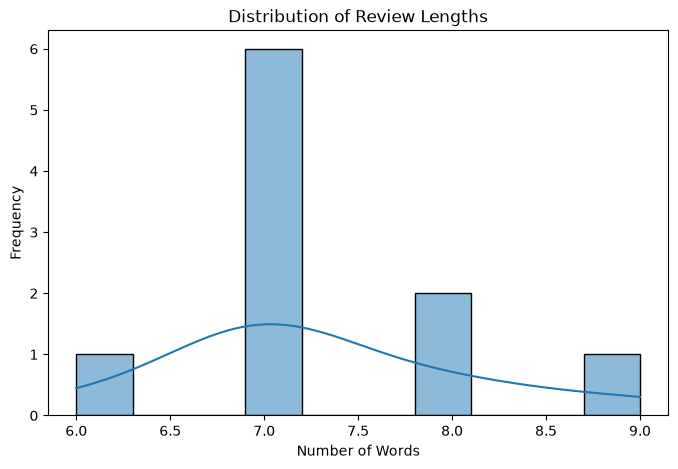

In [33]:
plt.figure(figsize=(8,5))
sns.histplot(df['review_length'], bins=10, kde=True)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [34]:
avg_length = df.groupby('sentiment')['review_length'].mean()

print(avg_length)

sentiment
negative    7.25
neutral     7.00
positive    7.40
Name: review_length, dtype: float64


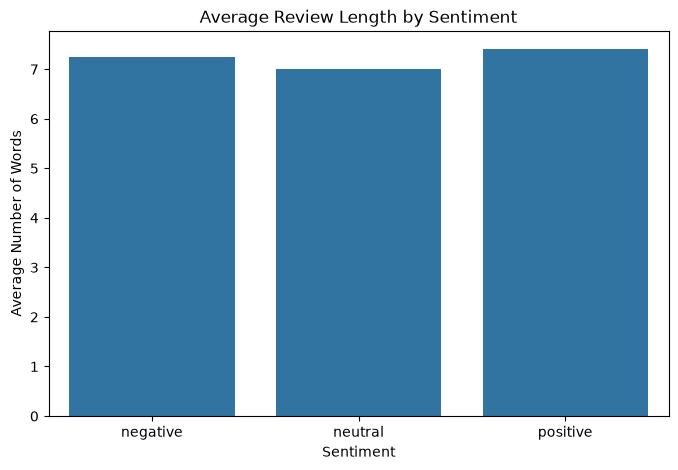

In [35]:
plt.figure(figsize=(8,5))
sns.barplot(x=avg_length.index, y=avg_length.values)

plt.title("Average Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Number of Words")

plt.show()

In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [37]:
tfidf = TfidfVectorizer(max_features=1000)

In [38]:
X = tfidf.fit_transform(df['lemmatized_text'])

In [39]:
print("TF-IDF Matrix Shape:", X.shape)

TF-IDF Matrix Shape: (10, 69)


In [40]:
print(tfidf.get_feature_names_out())

['absolutely' 'adapter' 'after' 'again' 'all' 'alternative' 'arrive'
 'available' 'average' 'build' 'cable' 'clean' 'completely' 'control'
 'customer' 'damage' 'day' 'decent' 'definitely' 'delivery' 'disappointed'
 'durable' 'easy' 'exceed' 'exceptional' 'expectation' 'extremely'
 'flawlessly' 'great' 'help' 'highly' 'interface' 'intuitive' 'item'
 'love' 'minute' 'miss' 'money' 'not' 'nothing' 'one' 'package'
 'performance' 'plenty' 'point' 'price' 'product' 'purchase' 'quality'
 'question' 'recommend' 'resolve' 'robust' 'service' 'setup' 'slow'
 'special' 'stop' 'student' 'support' 'ten' 'terrible' 'two' 'value'
 'well' 'within' 'work' 'worth' 'would']


In [41]:
tfidf_df = pd.DataFrame(
    X.toarray(),
    columns=tfidf.get_feature_names_out()
)

tfidf_df.head()

,absolutely,adapter,after,again,all,alternative,arrive,available,average,build,...,support,ten,terrible,two,value,well,within,work,worth,would
0,0.000000,0.0,0.000000,0.0,0.408248,0.0,0.000000,0.0,0.000000,0.0,...,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0
1,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.385682,0.0,0.000000,0.0,...,0.0,0.0,0.385682,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0
2,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.377964,0.0,...,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0
3,0.393893,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,...,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.334845,0.0,0.0
4,0.000000,0.0,0.366487,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,...,0.0,0.0,0.000000,0.366487,0.0,0.0,0.0,0.311547,0.0,0.0


In [42]:
X = tfidf.fit_transform(df['lemmatized_text'])
y = df['sentiment']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (10, 69)
Target Shape: (10,)


In [43]:
from sklearn.model_selection import train_test_split

In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

In [45]:
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Labels:")
print(y_train.value_counts())

print("\nTesting Labels:")
print(y_test.value_counts())

Training Features: (8, 69)
Testing Features: (2, 69)

Training Labels:
sentiment
positive    5
negative    2
neutral     1
Name: count, dtype: int64

Testing Labels:
sentiment
negative    2
Name: count, dtype: int64


In [46]:
from sklearn.naive_bayes import MultinomialNB

In [47]:
nb_model = MultinomialNB()

In [48]:
nb_model.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](3,)","[2.,1.,5.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](3,)","[-1.39,-2.08,-0.47]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U8](3,)","['negative','neutral','positive']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](3, 69)","[[0. ,0.38,0.37,...,0.31,0. ,0. ], [0. ,0. ,0. ,...,0. ,0. ,0. ], [0.39,0. ,0. ,...,0.33,0. ,0.36]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](3, 69)","[[-4.31,-3.99,-4. ,...,-4.04,-4.31,-4.31], [-4.27,-4.27,-4.27,...,-4.27,-4.27,-4.27], [-4.08,-4.41,-4.41,...,-4.12,-4.41,-4.11]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,69


In [49]:
y_pred_nb = nb_model.predict(X_test)

print("Actual Labels:")
print(y_test.values)

print("\nPredicted Labels:")
print(y_pred_nb)

Actual Labels:
<StringArray>
['negative', 'negative']
Length: 2, dtype: str

Predicted Labels:
['positive' 'positive']


In [50]:
from sklearn.linear_model import LogisticRegression

In [51]:
lr_model = LogisticRegression(max_iter=1000)

In [52]:
lr_model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [53]:
y_pred_lr = lr_model.predict(X_test)

print("Actual Labels:")
print(y_test.values)

print("\nPredicted Labels:")
print(y_pred_lr)

Actual Labels:
<StringArray>
['negative', 'negative']
Length: 2, dtype: str

Predicted Labels:
['positive' 'positive']


In [54]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [55]:
print("NAIVE BAYES RESULTS")

print("Accuracy:", accuracy_score(y_test, y_pred_nb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb, zero_division=0))

NAIVE BAYES RESULTS
Accuracy: 0.0

Classification Report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00       2.0
    positive       0.00      0.00      0.00       0.0

    accuracy                           0.00       2.0
   macro avg       0.00      0.00      0.00       2.0
weighted avg       0.00      0.00      0.00       2.0



In [56]:
print("LOGISTIC REGRESSION RESULTS")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

LOGISTIC REGRESSION RESULTS
Accuracy: 0.0

Classification Report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00       2.0
    positive       0.00      0.00      0.00       0.0

    accuracy                           0.00       2.0
   macro avg       0.00      0.00      0.00       2.0
weighted avg       0.00      0.00      0.00       2.0



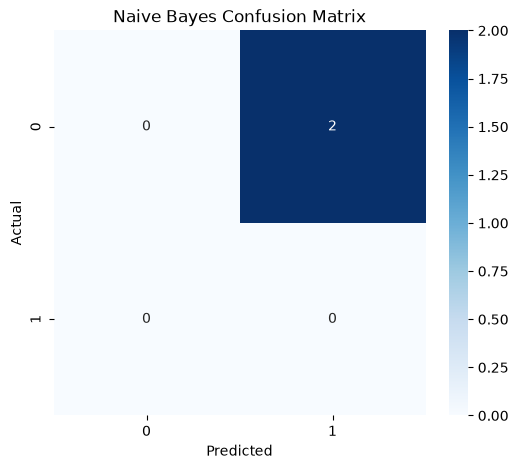

In [57]:
plt.figure(figsize=(6,5))

sns.heatmap(
    confusion_matrix(y_test, y_pred_nb),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

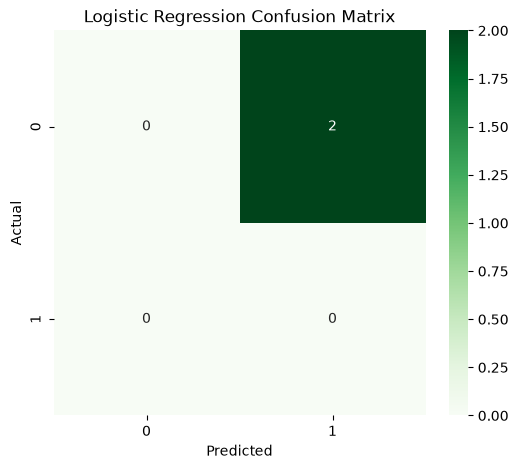

In [58]:
plt.figure(figsize=(6,5))

sns.heatmap(
    confusion_matrix(y_test, y_pred_lr),
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [59]:
def predict_sentiment(review):

    cleaned = review.lower()
    cleaned = re.sub(r'http\S+|www\S+', '', cleaned)
    cleaned = re.sub(r'[^a-zA-Z\s]', '', cleaned)
    cleaned = re.sub(r'\s+', ' ', cleaned).strip()

    tokens = wordpunct_tokenize(cleaned)

    filtered = [
        word for word in tokens
        if word not in custom_stopwords
    ]

    processed = ' '.join(filtered)
    lemmatized = lemmatize_text(processed)
    vectorized = tfidf.transform([lemmatized])
    prediction = lr_model.predict(vectorized)

    return prediction[0]

In [ ]:
review = input("Enter a customer review: ")
result = predict_sentiment(review)

print("Predicted Sentiment:", result)